# 05 · Hyperliquid L4: ciclo di vita degli ordini (E4)

Il dataset di Albers et al. (2026) registra ogni variazione del book di Hyperliquid per ordine e utente (L4). Una rimozione non distingue esecuzione e cancellazione: il parser unisce i book diff con i trade pubblici tramite l'`oid` del maker (nei trade `side` è l'aggressore e `side_info` è [acquirente, venditore]) e attribuisce a esecuzioni solo il volume effettivamente scambiato.

Campione ristretto: BTC-PERP, sei ore (1-3 dicembre 2025, 08 e 14 UTC). Calibrazione delle soglie: 1° dicembre ore 08; validazione: 1° dicembre ore 14; test: le quattro ore successive. Quota di 0,01 BTC; i diff non hanno timestamp, quindi durata e latenza sono in eventi.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")
validation = R.load(ROOT, "validation")
selected = R.load_json(ROOT, "selected_params")

def dataset_section(name, fee_column, unit):
    stats = R.model_table(test, name)
    display(stats.round(2))
    bias = R.fill_bias(test, name)
    display(Markdown("**Fill maker rispetto alla coda FIFO** (mediana e intervallo tra le sessioni)"))
    display(bias.describe().loc[["50%", "min", "max"]].rename(columns=R.LABELS).round(2))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    R.bar_by_model(axes[0], stats, "P&L lordo medio per sessione (IC 95%)", unit)
    linthresh = 10 ** np.ceil(np.log10(max(1.0, abs(stats.loc["coda FIFO", "media"]))))
    axes[0].set_yscale("symlog", linthresh=linthresh, linscale=0.5)
    med = bias.median()
    axes[1].bar([R.LABELS[m] for m in med.index], med, color=[R.COLORS[m] for m in med.index], width=0.6)
    for k, v in enumerate(med):
        axes[1].text(k, v * 1.08, f"{it(v, 1)}×", ha="center", va="bottom", color=R.INK)
    axes[1].axhline(1, color=R.INK, linewidth=0.8)
    axes[1].set(yscale="log", title="Fill maker / fill coda FIFO (mediana)", ylim=(0.5, med.max() * 3))
    axes[1].grid(axis="x", visible=False)
    return stats, fig

ingest = pd.DataFrame(R.load_json(ROOT, "ingest/hyperliquid")["sessions"]).set_index("session")
ingest["volume trade attribuito"] = ingest.fill_volume / ingest.trade_volume
display(ingest[["diffs", "rows", "fill_events", "cancel_events", "unknown_order_diffs", "volume trade attribuito", "seconds"]]
        .rename(columns={"diffs": "diff BTC", "rows": "eventi", "fill_events": "esecuzioni", "cancel_events": "cancellazioni",
                         "unknown_order_diffs": "diff su ordini precedenti"}).round(3))
quality = R.load(ROOT, "quality").query("dataset == 'hyperliquid'").set_index("session")
display(quality[["events", "records", "ts_decreasing", "unknown_order", "duplicate_add", "overfill", "crossed_share"]])

,diff BTC,eventi,esecuzioni,cancellazioni,diff su ordini precedenti,volume trade attribuito,seconds
session,,,,,,,
20251201T08,2420117,2405368,17444,1186941,14751,0.983,31.891
20251201T14,4031702,4001037,36484,1967011,30667,0.994,69.158
20251202T08,2470744,2452946,23698,1205535,17800,0.965,34.319
20251202T14,4808729,4766912,49791,2339637,41821,0.972,87.622
20251203T08,2622419,2605854,19658,1285047,16569,0.978,34.432
20251203T14,5536288,5485893,64993,2687374,50401,0.968,95.930


,events,records,ts_decreasing,unknown_order,duplicate_add,overfill,crossed_share
session,,,,,,,
20251201T08,2405368.0,2405366,0,0.0,0.0,0.0,0.0
20251201T14,4001037.0,4001034,0,0.0,0.0,0.0,0.0
20251202T08,2452946.0,2452901,0,0.0,0.0,0.0,0.0
20251202T14,4766912.0,4766911,0,0.0,0.0,0.0,0.0
20251203T08,2605854.0,2605842,0,0.0,0.0,0.0,0.0
20251203T14,5485893.0,5485862,0,0.0,0.0,0.0,0.0


**Validazione**: P&L netto medio per ora con coda FIFO, tier 0 (USD)

Parametri scelti: `{'vol_quantile': 0.5, 'max_order_age_events': 5000, 'volatility_window': 5000}` (finestra e durata in eventi).

,sessioni,media,ic95_basso,ic95_alto,quota_positive
touch,4,3814.26,2798.01,4830.51,1.0
price-through,4,-32.58,-35.34,-29.82,0.0
cross,4,-28.60,-32.09,-25.50,0.0
coda FIFO,4,-3.25,-3.88,-2.18,0.0


**Fill maker rispetto alla coda FIFO** (mediana e intervallo tra le sessioni)

model,touch,price-through,cross,coda FIFO
50%,2371.72,1.33,1.10,1.0
min,2198.63,0.97,0.90,1.0
max,2627.70,1.99,1.59,1.0


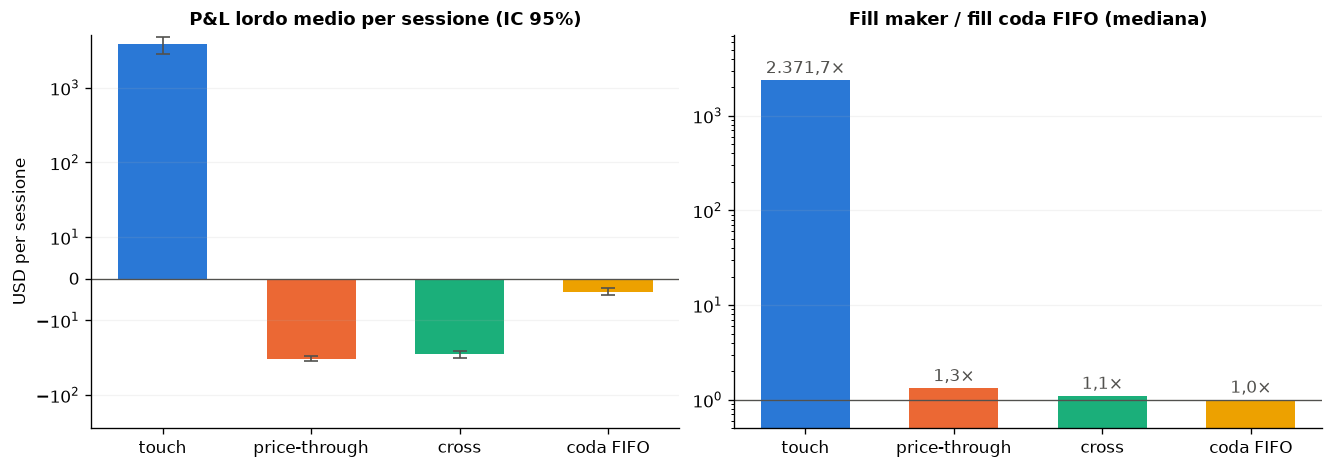

,edge maker,costo di liquidazione,P&L di inventario,P&L lordo,adverse selection (markout),commissioni,P&L netto tier 0
touch,3836.851,-5.465,-17.129,3814.258,-17.300,-97692.688,-93878.430
price-through,-0.085,-7.652,-24.840,-32.578,-32.427,-190.308,-222.885
cross,-7.994,-5.541,-15.060,-28.595,-16.506,-164.182,-192.777
coda FIFO,0.594,-1.273,-2.567,-3.246,-3.584,-44.036,-47.282


,coppie,bilaterali,unilaterali,senza fill,con fill parziale
touch,"1,447,249",99.9%,0.1%,0.0%,0.0%
price-through,"1,504",6.5%,90.4%,3.1%,0.0%
cross,"1,480",5.1%,79.5%,15.3%,0.0%
coda FIFO,"1,479",7.8%,27.6%,64.6%,16.4%


**Filtro di volatilità: P&L netto per ora (USD, tier 0), con filtro e sempre attiva**

,sessioni,con filtro,sempre attiva,differenza,IC95 basso,IC95 alto,sessioni migliori con filtro,quota record attivi,fill con filtro,fill sempre attiva,liquidazioni per volatilità
modello,,,,,,,,,,,
touch,4,"-93,878.43","-152,200.57","58,322.14","21,229.30","95,414.99",100%,32%,"723,358","1,178,420",207.2
price-through,4,-222.89,-527.89,305.00,75.00,535.01,100%,32%,389,954,249.2
cross,4,-192.78,-525.62,332.84,87.90,577.78,100%,32%,332,910,203.2
coda FIFO,4,-47.28,-122.34,75.05,22.26,127.84,100%,32%,308,725,67.5


In [2]:
display(Markdown("**Validazione**: P&L netto medio per ora con coda FIFO, tier 0 (USD)"))
display(R.validation_grid(validation, "hyperliquid", "net_tier0").style.format("{:.1f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"Parametri scelti: `{selected['hyperliquid']['params']}` (finestra e durata in eventi)."))
stats, fig = dataset_section("hyperliquid", "fees_tier0", "USD per sessione")
fig.savefig(FIGURES / "hyperliquid_test.png", dpi=180, bbox_inches="tight")
plt.show()
dec = R.decomposition(test, "hyperliquid", "fees_tier0")
display(dec.rename(columns={**R.DECOMPOSITION_LABELS, "final_equity": "P&L lordo", "adverse_selection": "adverse selection (markout)", "net": "P&L netto tier 0"}).round(3))
display(R.fill_rates(test, "hyperliquid").style.format({"coppie": "{:,.0f}", **{c: "{:.1%}" for c in ["bilaterali", "unilaterali", "senza fill", "con fill parziale"]}}))
ablation = R.load(ROOT, "ablation")
display(Markdown("**Filtro di volatilità: P&L netto per ora (USD, tier 0), con filtro e sempre attiva**"))
display(R.filter_effect(test, ablation, "hyperliquid", "net_tier0").style.format(
    {c: "{:,.2f}" for c in ["con filtro", "sempre attiva", "differenza", "IC95 basso", "IC95 alto"]}
    | {"sessioni migliori con filtro": "{:.0%}", "quota record attivi": "{:.0%}", "fill con filtro": "{:,.0f}",
       "fill sempre attiva": "{:,.0f}", "liquidazioni per volatilità": "{:.1f}"}))

In [3]:
variants = R.load(ROOT, "variants")
display(Markdown("**Varianti** (coda FIFO, P&L netto tier 0, differenza appaiata con la strategia base)"))
display(R.variant_effect(test, variants, "hyperliquid", "net_tier0", fee_column="fees_tier0").style.format({"P&L netto medio": "{:,.2f}", "IC95 basso": "{:,.2f}", "IC95 alto": "{:,.2f}", "sessioni positive": "{:.0%}",
       "differenza vs base": "{:+,.2f}", "diff IC95 basso": "{:+,.2f}", "diff IC95 alto": "{:+,.2f}",
       "edge maker": "{:,.2f}", "costo di liquidazione": "{:,.2f}", "P&L di inventario": "{:,.2f}",
       "commissioni": "{:,.2f}", "fill maker": "{:,.0f}", "coppie bilaterali": "{:.0%}", "liquidazioni a mercato": "{:,.1f}"}))
display(Markdown(f"Parametri scelti in validazione: `{selected['variants']['hyperliquid']}`"))

**Varianti** (coda FIFO, P&L netto tier 0, differenza appaiata con la strategia base)

,sessioni,P&L netto medio,IC95 basso,IC95 alto,sessioni positive,differenza vs base,diff IC95 basso,diff IC95 alto,edge maker,costo di liquidazione,P&L di inventario,commissioni,fill maker,coppie bilaterali,liquidazioni a mercato
variante,,,,,,,,,,,,,,,
base,4,-47.28,-56.71,-34.16,0%,+0.00,+0.00,+0.00,0.59,-1.27,-2.57,-44.04,308,8%,117.5
inventory skew,4,-39.33,-44.33,-31.14,0%,+7.95,+1.72,+14.18,0.53,-1.43,-2.75,-35.68,274,10%,92.5
filtro di imbalance,4,-6.40,-9.87,-3.92,0%,+40.88,+28.79,+49.76,0.07,-0.07,0.01,-6.41,18,0%,13.5
skew + imbalance,4,-5.64,-8.43,-3.58,0%,+41.65,+29.50,+50.35,0.07,-0.37,0.34,-5.67,16,0%,11.2


Parametri scelti in validazione: `{'imbalance': {'params': {'imbalance_threshold': 0.3}, 'validation_mean': -6.791231088000001, 'metric': 'net_tier0'}, 'skew': {'params': {'inventory_mode': 'skew', 'skew_ticks': 0, 'max_hold_factor': 2}, 'validation_mean': -40.76278217300013, 'metric': 'net_tier0'}, 'skew_imbalance': {'params': {'inventory_mode': 'skew', 'skew_ticks': 0, 'max_hold_factor': 10, 'imbalance_threshold': 0.3}, 'validation_mean': -5.768335911999877, 'metric': 'net_tier0'}}`

In [4]:
from market_making_tesi.pipeline import DATASETS, events, l2_view, session_list
spec = DATASETS["hyperliquid"]
path = next(p for s, sym, p in session_list(ROOT, spec) if s == "20251202T08")
spreads = np.fromiter((s.spread for s in l2_view(events(spec, path, "BTC"))), dtype=float)
one_tick = (spreads <= 1.0 + 1e-9).mean()
q = stats.loc["coda FIFO"]
bias = R.fill_bias(test, "hyperliquid").median()
dq = dec.loc["coda FIFO"]
display(Markdown(
    f"**Esito E4.** Con la coda FIFO il P&L lordo medio è {it(q['media'], 2)} USD per ora (positivo nel "
    f"{pct(q['quota_positive'], 0)} delle sessioni di test); `touch` attribuisce {it(bias['touch'])} volte i fill della coda. "
    f"Nell'ora del 2/12 alle 08 lo spread è di un tick (1 USD) nel {pct(one_tick)} dei record: l'edge maker per ora "
    f"({it(dq['maker_edge'], 2)} USD) è piccolo rispetto alle commissioni al tier base ({it(-dq['fees'], 2)} USD)."))

**Esito E4.** Con la coda FIFO il P&L lordo medio è -3,25 USD per ora (positivo nel 0% delle sessioni di test); `touch` attribuisce 2.372 volte i fill della coda. Nell'ora del 2/12 alle 08 lo spread è di un tick (1 USD) nel 96,4% dei record: l'edge maker per ora (0,59 USD) è piccolo rispetto alle commissioni al tier base (44,04 USD).